# Childhood Heart Screening Tracker

A tracker that follows a child's daily activity, resting heart rate, breathing and symptoms, and flags when the last 7 days stop matching that child's usual pattern. Built for hackathon topic 2 (the tracker), adapted to children's heart health.

**Real data:** CirCor DigiScope pediatric murmur data (age mix, murmur rate, BMI), UCI Heart Disease (adults, side analysis) and WHO death rates for rheumatic heart disease.
**Simulated:** the 300 children, their 30 days of logs, the symptoms and the worse weeks. The gaps between murmur-flagged and other children are my assumptions.

> Educational project only. Not medical advice, and no real patient data is used in the tracker.



## 0. Setup

In [42]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from scipy import stats
from IPython.display import display
from google.colab import drive

drive.mount('/content/drive')
folder = '/content/drive/MyDrive/hackathon'
os.makedirs(folder, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load the real data

In [43]:
# CirCor DigiScope: one row per child (real data)
heart_track = pd.read_csv(f'{folder}/training_data.csv')

# UCI Heart Disease, Cleveland file (real data, adults)
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]
heart_disease = pd.read_csv(f'{folder}/processed.cleveland.data', names=columns, na_values='?')

# WHO rheumatic heart disease death rates by country and year (via Our World in Data)
death_rate = pd.read_csv(f'{folder}/death-rate-from-rheumatic-heart-disease-who-ghe-age-standardized.csv')

print("CirCor:", heart_track.shape, "| UCI:", heart_disease.shape, "| WHO:", death_rate.shape)
display(heart_track.head())
heart_track.info()

CirCor: (942, 23) | UCI: (303, 14) | WHO: (4422, 4)


,Patient ID,Recording locations:,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Systolic murmur pitch,Systolic murmur quality,Diastolic murmur timing,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Outcome,Campaign,Additional ID
0,2530,AV+PV+TV+MV,Child,Female,98.0,15.9,False,Absent,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.1,False,Present,AV+MV+PV+TV,TV,...,High,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
2,9983,AV+PV+TV+MV,Child,Male,115.0,19.1,False,Unknown,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.9,False,Present,TV,TV,...,Low,Blowing,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
4,14241,AV+PV+TV+MV,Child,Male,87.0,11.2,False,Present,AV+MV+PV+TV,PV,...,Low,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 942 entries, 0 to 941
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient ID                942 non-null    int64  
 1   Recording locations:      942 non-null    object 
 2   Age                       868 non-null    object 
 3   Sex                       942 non-null    object 
 4   Height                    826 non-null    float64
 5   Weight                    837 non-null    float64
 6   Pregnancy status          942 non-null    bool   
 7   Murmur                    942 non-null    object 
 8   Murmur locations          179 non-null    object 
 9   Most audible location     179 non-null    object 
 10  Systolic murmur timing    178 non-null    object 
 11  Systolic murmur shape     178 non-null    object 
 12  Systolic murmur grading   178 non-null    object 
 13  Systolic murmur pitch     178 non-null    object 
 14  Systolic m

## 2. CirCor: murmur, age and BMI (real data)

In [44]:
def user_profile(patient_id):
    patient_data = heart_track[heart_track['Patient ID'] == patient_id]

    if patient_data.empty:
        return f"Patient ID {patient_id} not found."

    row = patient_data.iloc[0]
    age = row['Age']
    sex = row['Sex']
    height_cm = row['Height']
    weight_kg = row['Weight']

    # Calculate BMI if height and weight are available
    if pd.notna(height_cm) and pd.notna(weight_kg) and height_cm > 0:
        height_m = height_cm / 100.0
        bmi = round(weight_kg / (height_m ** 2), 2)
    else:
        bmi = None

    return {
        'patient_id': int(patient_id),
        'age': age,
        'sex': sex,
        'height_cm': height_cm,
        'weight_kg': weight_kg,
        'bmi': bmi
    }

user_profile(heart_track['Patient ID'].iloc[0])

{'patient_id': 2530,
 'age': 'Child',
 'sex': 'Female',
 'height_cm': np.float64(98.0),
 'weight_kg': np.float64(15.9),
 'bmi': np.float64(16.56)}

In [45]:
# BMI for every child, then remove impossible values (data entry errors)
heart_track['BMI'] = heart_track['Weight'] / ((heart_track['Height'] / 100.0) ** 2)
clean = heart_track[(heart_track["BMI"] >= 10) & (heart_track["BMI"] <= 40)]
print("rows kept after BMI cleaning:", len(heart_track), "->", len(clean))

present = clean.loc[clean["Murmur"] == "Present", "BMI"].dropna()
absent = clean.loc[clean["Murmur"] == "Absent", "BMI"].dropna()

welch = stats.ttest_ind(present, absent, equal_var=False)
mw = stats.mannwhitneyu(present, absent)
print(f"Mean BMI with murmur: {present.mean():.1f} | without: {absent.mean():.1f}")
print(f"Welch t-test: t = {welch.statistic:.2f}, p = {welch.pvalue:.4f}")
print(f"Mann-Whitney U test: p = {mw.pvalue:.5f}")

rows kept after BMI cleaning: 942 -> 816
Mean BMI with murmur: 16.7 | without: 17.6
Welch t-test: t = -3.13, p = 0.0019
Mann-Whitney U test: p = 0.00012


In [46]:
print(heart_track["Murmur"].value_counts())
print(heart_track["Murmur"].value_counts(normalize=True).round(3))

print("\n---- Murmur rate by age group ----")
print(pd.crosstab(heart_track["Age"], heart_track["Murmur"], normalize="index").round(3))

print("\n---- Mean BMI by murmur within age group ----")
print(clean.groupby(["Age", "Murmur"])["BMI"].mean().round(1).unstack())

Murmur
Absent     695
Present    179
Unknown     68
Name: count, dtype: int64
Murmur
Absent     0.738
Present    0.190
Unknown    0.072
Name: proportion, dtype: float64

---- Murmur rate by age group ----
Murmur      Absent  Present  Unknown
Age                                 
Adolescent   0.736    0.222    0.042
Child        0.745    0.199    0.056
Infant       0.603    0.198    0.198
Neonate      0.667    0.167    0.167

---- Mean BMI by murmur within age group ----
Murmur      Absent  Present  Unknown
Age                                 
Adolescent    20.3     20.6     17.4
Child         17.3     16.2     18.1
Infant        18.0     16.3     18.8
Neonate       14.5     14.0     11.8


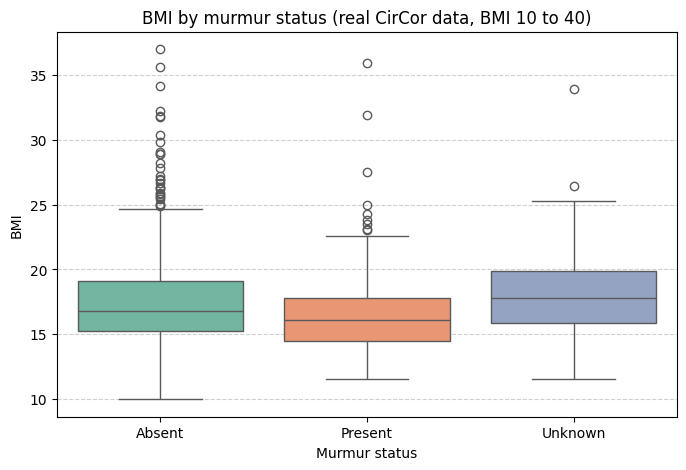

In [47]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean[clean["Murmur"].isin(["Absent", "Present", "Unknown"])],
            x="Murmur", y="BMI", hue="Murmur", palette="Set2", legend=False)
plt.title("BMI by murmur status (real CirCor data, BMI 10 to 40)")
plt.xlabel("Murmur status")
plt.ylabel("BMI")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

**What this shows (real data):** BMI is lower in children with a murmur, and the difference is significant (see the p-values above). Within age groups it is lower in Child, Infant and Neonate and slightly higher in Adolescents. This is an association, not a cause, and some groups are small.

In [48]:
# Does the murmur rate depend on age group? Known results only, Neonate merged into Infant (too few children).
known = heart_track[heart_track["Murmur"].isin(["Absent", "Present"])].copy()
known["Age2"] = known["Age"].replace({"Neonate": "Infant"})

table2 = pd.crosstab(known["Age2"], known["Murmur"])
print(table2)
chi2, p, dof, expected = stats.chi2_contingency(table2)
print(f"chi-square = {chi2:.2f}, dof = {dof}, p = {p:.2f}")

Murmur      Absent  Present
Age2                       
Adolescent      53       16
Child          495      132
Infant          80       26
chi-square = 0.74, dof = 2, p = 0.69


**Chi-square result:** a first test that included "Unknown" looked significant, but that came from infants more often having an Unknown result and from very small Neonate counts. With known results only and Neonate merged into Infant, murmur rates do not differ by age group (about 21% to 25% in each group).

## 3. UCI Heart Disease (adults, side analysis)

disease
no disease    164
disease       139
Name: count, dtype: int64
Max heart rate: disease 139 bpm vs no disease 158 bpm (t = -7.86, p = 9.1e-14)


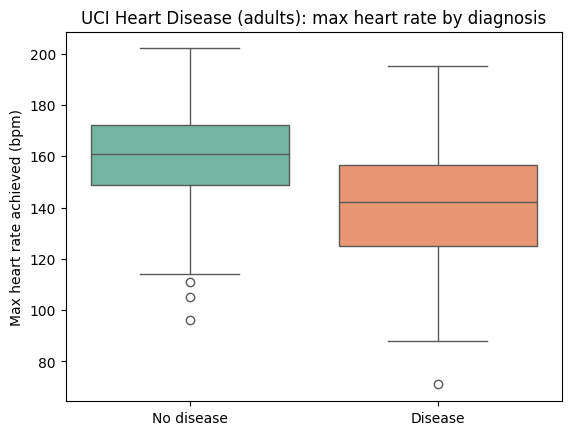

In [49]:
heart_disease["disease"] = (heart_disease["target"] > 0).astype(int)
print(heart_disease["disease"].value_counts().rename({0: "no disease", 1: "disease"}))

with_d = heart_disease.loc[heart_disease["disease"] == 1, "thalach"].dropna()
no_d = heart_disease.loc[heart_disease["disease"] == 0, "thalach"].dropna()
uci_t = stats.ttest_ind(with_d, no_d, equal_var=False)
print(f"Max heart rate: disease {with_d.mean():.0f} bpm vs no disease {no_d.mean():.0f} bpm (t = {uci_t.statistic:.2f}, p = {uci_t.pvalue:.2g})")

sns.boxplot(data=heart_disease, x="disease", y="thalach", hue="disease", palette="Set2", legend=False)
plt.xticks([0, 1], ["No disease", "Disease"])
plt.xlabel("")
plt.ylabel("Max heart rate achieved (bpm)")
plt.title("UCI Heart Disease (adults): max heart rate by diagnosis")
plt.show()

This is adult data from a different study, so it is kept as a side analysis and is not mixed with the children's data.

## 4. Simulate the children and their daily logs

Real numbers from CirCor (age mix, murmur rate per age group, BMI and height per age group and murmur status) set up the 300 simulated children. The daily values and the extra effect for murmur-flagged children are **my assumptions**, not findings.

In [50]:
N = 300
days = 30
rng = np.random.default_rng(42)

# learned from the real CirCor data
age_weights = heart_track["Age"].value_counts(normalize=True).sort_index()
murmur_rate = pd.crosstab(heart_track["Age"], heart_track["Murmur"], normalize="index").round(3)["Present"]
stats_tbl = (clean[clean["Murmur"].isin(["Present", "Absent"])]
             .groupby(["Age", "Murmur"])[["BMI", "Height"]].agg(["mean", "std"]))

ages = rng.choice(age_weights.index, size=N, p=age_weights.values)

rows = []
for i, a in enumerate(ages, start=1):
    flagged = rng.random() < murmur_rate[a]
    key = (a, "Present" if flagged else "Absent")
    t = stats_tbl.loc[key]
    bmi = max(10, rng.normal(t[("BMI", "mean")], np.nan_to_num(t[("BMI", "std")], nan=2)))
    height = max(40, rng.normal(t[("Height", "mean")], np.nan_to_num(t[("Height", "std")], nan=5)))
    rows.append({
        "child_id": i,
        "age group": a,
        "sex": rng.choice(["Female", "Male"]),
        "height_cm": round(height, 1),
        "bmi": round(bmi, 1),
        "murmur_flagged": int(flagged)
    })
profiles = pd.DataFrame(rows)

# rough baselines per age group: (active minutes, resting heart rate, breaths per minute). ASSUMPTIONS.
base = {
    "Neonate": (30, 135, 45),
    "Infant": (60, 120, 32),
    "Child": (100, 90, 22),
    "Adolescent": (90, 75, 16)
}

log_rows = []
for _, c in profiles.iterrows():
    act, hr, br = base[c["age group"]]
    f = c["murmur_flagged"]
    for d in range(1, days + 1):
        log_rows.append({
            "child_id": c["child_id"],
            "day": d,
            "active_minutes": max(0, rng.normal(act - 0.25 * act * f, 0.2 * act)),
            "resting_hr": rng.normal(hr + 8 * f, 6),
            "breathing_per_minute": rng.normal(br + 4 * f, 3),
            "energy_1to5": int(np.clip(round(rng.normal(4 - 1.2 * f, 0.8)), 1, 5)),
        })
logs = pd.DataFrame(log_rows).round(1)

full = logs.merge(profiles, on="child_id")
print(profiles.shape, logs.shape, full.shape)
display(profiles.head())

(300, 6) (9000, 6) (9000, 11)


,child_id,age group,sex,height_cm,bmi,murmur_flagged
0,1,Child,Female,111.0,17.0,0
1,2,Child,Male,111.3,10.0,0
2,3,Infant,Female,61.3,18.7,0
3,4,Child,Female,83.5,23.2,0
4,5,Child,Female,115.1,16.2,0


### Symptom table

Symptoms come from NHLBI, Mayo Clinic, CDC and NHS pages on congenital heart defects. The daily chances are my assumptions. Urgent signs such as blue lips or fainting are left out of the daily log on purpose, because they need medical care, not tracking.

In [51]:
symptom_table = pd.DataFrame({
    "symptom": ["fast_breathing", "tires_easily", "short_breath_activity", "poor_weight_gain"],
    "age_groups": [["Neonate", "Infant"],
                   ["Neonate", "Infant", "Child", "Adolescent"],
                   ["Child", "Adolescent"],
                   ["Infant", "Child"]],
    "chance_flagged": [0.20, 0.25, 0.20, 0.15],
    "chance_not_flagged": [0.05, 0.08, 0.04, 0.04],
    "source": ["NHLBI, Mayo, CDC", "NHLBI, Mayo", "NHLBI, Mayo", "NHS, Mayo"],
})
display(symptom_table)

,symptom,age_groups,chance_flagged,chance_not_flagged,source
0,fast_breathing,"[Neonate, Infant]",0.20,0.05,"NHLBI, Mayo, CDC"
1,tires_easily,"[Neonate, Infant, Child, Adolescent]",0.25,0.08,"NHLBI, Mayo"
2,short_breath_activity,"[Child, Adolescent]",0.20,0.04,"NHLBI, Mayo"
3,poor_weight_gain,"[Infant, Child]",0.15,0.04,"NHS, Mayo"


In [52]:
symptoms = symptom_table["symptom"].to_list()

for _, row in symptom_table.iterrows():
    chance = np.where(full["murmur_flagged"] == 0, row["chance_not_flagged"], row["chance_flagged"])
    is_eligible = full["age group"].isin(row["age_groups"])
    random_trigger = rng.random(len(full)) < chance
    full[row["symptom"]] = (is_eligible & random_trigger).astype(int)

print("Share of days with each symptom, by murmur status:")
display(full.groupby("murmur_flagged")[symptoms].mean().round(3))

Share of days with each symptom, by murmur status:


,fast_breathing,tires_easily,short_breath_activity,poor_weight_gain
murmur_flagged,,,,
0,0.005,0.079,0.035,0.037
1,0.021,0.263,0.179,0.143


### Worse weeks

So that the tracker has something to catch, 40% of the murmur-flagged children get a worse final week (days 24 to 30): less activity, a higher heart rate and more symptom days. Symptoms are then cleared again for age groups where they do not apply.

In [53]:
flagged_all = full[full["murmur_flagged"] == 1]["child_id"].unique()
episode_ids = rng.choice(flagged_all, size=int(len(flagged_all) * 0.4), replace=False)

mask = full["child_id"].isin(episode_ids) & (full["day"] > 23)
full.loc[mask, "active_minutes"] *= 0.6
full.loc[mask, "resting_hr"] *= 1.12
for s in symptoms:
    full.loc[mask, s] = (rng.random(mask.sum()) < 0.6).astype(int)

# symptoms only for the age groups they apply to
for _, row in symptom_table.iterrows():
    not_eligible = ~full["age group"].isin(row["age_groups"])
    full.loc[not_eligible, row["symptom"]] = 0

full = full.round(1)
full.to_csv(f'{folder}/full.csv', index=False)
print("children with a worse final week:", len(episode_ids))
print("saved full table:", full.shape)

children with a worse final week: 24
saved full table: (9000, 15)


## 5. Analysis of the simulated logs

In [54]:
# Average each child first, so the same child is not counted 30 times
child_means = (full.groupby(["child_id", "murmur_flagged", "age group"])
               [["active_minutes", "resting_hr"]].mean().reset_index())
f = child_means[child_means["murmur_flagged"] == 1]
nf = child_means[child_means["murmur_flagged"] == 0]

for col, label in [("active_minutes", "Active minutes"), ("resting_hr", "Resting heart rate")]:
    r = stats.ttest_ind(f[col], nf[col], equal_var=False)
    print(f"{label}: flagged {f[col].mean():.1f} vs others {nf[col].mean():.1f} (t = {r.statistic:.2f}, p = {r.pvalue:.2g})")

# does resting heart rate differ across age groups? (one-way ANOVA)
groups = [g["resting_hr"].values for _, g in child_means.groupby("age group")]
anova = stats.f_oneway(*groups)
print(f"Resting heart rate across age groups: F = {anova.statistic:.1f}, p = {anova.pvalue:.2g}")
display(child_means.groupby("age group")["resting_hr"].mean().round(1))

Active minutes: flagged 69.1 vs others 94.4 (t = -15.17, p = 1.2e-29)
Resting heart rate: flagged 101.6 vs others 92.9 (t = 5.35, p = 6.2e-07)
Resting heart rate across age groups: F = 1234.7, p = 1.2e-144


,resting_hr
age group,
Adolescent,76.5
Child,91.9
Infant,121.7


These gaps were built into the simulation, so the tests show that the tracker can detect them. They are not medical findings. Resting heart rate differs a lot by age group in the simulation, which is why its murmur gap is smaller than the activity gap.

## 6. The tracker

Each child is compared with their own earlier days. The last 7 days are the recent window and every earlier day is the child's usual level. A flag appears when:

- average active minutes in the last 7 days fall below 80% of the usual level,
- average resting heart rate rises above 110% of the usual level, or
- a symptom appears on 4 or more of the last 7 days.

These thresholds are design choices, not medical rules.

In [55]:
class ChildTracker:
    def __init__(self, child_id):
        self.child_id = child_id
        self.logs = full[full["child_id"] == child_id].sort_values("day").reset_index(drop=True)

    def add_log(self, **values):
        new_day = int(self.logs["day"].max()) + 1
        row = self.logs.iloc[-1].to_dict()
        row.update(values)
        row["day"] = new_day
        self.logs = pd.concat([self.logs, pd.DataFrame([row])], ignore_index=True)

    def status(self, window=7):
        recent = self.logs.tail(window)
        base = self.logs.iloc[:-window]
        reasons = []
        if recent["active_minutes"].mean() < 0.8 * base["active_minutes"].mean():
            reasons.append("activity dropped more than 20% vs baseline")
        if recent["resting_hr"].mean() > 1.1 * base["resting_hr"].mean():
            reasons.append("resting heart rate rose more than 10% vs baseline")
        for s in symptoms:
            if recent[s].sum() > 3:
                reasons.append(f"{s} on {int(recent[s].sum())} of the last {window} days")
        return reasons

    def report(self):
        reasons = self.status()
        if reasons:
            return f"Child {self.child_id}: FLAG - " + "; ".join(reasons) + ". Worth asking a pediatrician."
        return f"Child {self.child_id}: no flag."

In [56]:
# How many children does the tracker flag?
flag_df = pd.DataFrame({
    "child_id": sorted(full["child_id"].unique()),
})
flag_df["reasons"] = [len(ChildTracker(c).status()) for c in flag_df["child_id"]]
flag_df = flag_df.merge(profiles[["child_id", "murmur_flagged"]], on="child_id")
flag_df["flagged"] = flag_df["reasons"] > 0
print("Children flagged by the tracker, by murmur status:")
display(flag_df.groupby("murmur_flagged")["flagged"].agg(flagged="sum", children="count"))

# Demo: a steady child, then five bad days added with add_log
steady_id = int(flag_df[flag_df["flagged"] == False]["child_id"].iloc[0])
t = ChildTracker(steady_id)
print("Before:", t.report())
for i in range(5):
    t.add_log(active_minutes=40, resting_hr=130, tires_easily=1, short_breath_activity=1)
print("After: ", t.report())

Children flagged by the tracker, by murmur status:


,flagged,children
murmur_flagged,,
0,1,239
1,31,61


Before: Child 1: no flag.
After:  Child 1: FLAG - activity dropped more than 20% vs baseline; resting heart rate rose more than 10% vs baseline; tires_easily on 5 of the last 7 days; short_breath_activity on 5 of the last 7 days. Worth asking a pediatrician.


Child 30 | Child | Male | BMI 10.4 | murmur flagged: 1


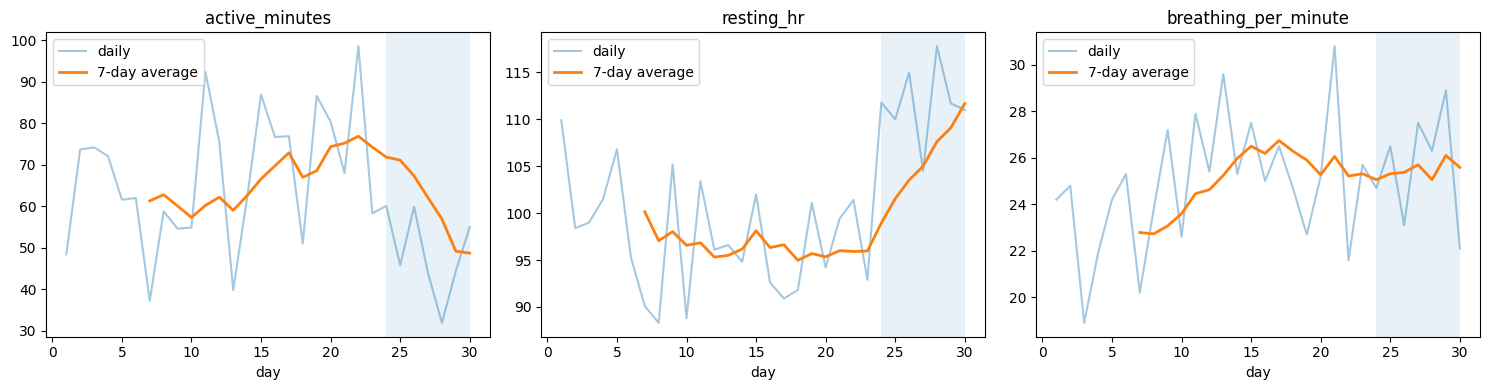

Child 30: FLAG - activity dropped more than 20% vs baseline; resting heart rate rose more than 10% vs baseline; tires_easily on 5 of the last 7 days; short_breath_activity on 5 of the last 7 days; poor_weight_gain on 6 of the last 7 days. Worth asking a pediatrician.


In [57]:
def show_child(child_id):
    c = full[full["child_id"] == child_id].sort_values("day")
    info = c.iloc[0]
    print(f"Child {child_id} | {info['age group']} | {info['sex']} | BMI {info['bmi']} | murmur flagged: {info['murmur_flagged']}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, col in zip(axes, ["active_minutes", "resting_hr", "breathing_per_minute"]):
        ax.plot(c["day"], c[col], alpha=0.4, label="daily")
        ax.plot(c["day"], c[col].rolling(7).mean(), linewidth=2, label="7-day average")
        ax.axvspan(c["day"].max() - 6, c["day"].max(), alpha=0.1)
        ax.set_title(col)
        ax.set_xlabel("day")
        ax.legend()
    plt.tight_layout()
    plt.show()
    print(ChildTracker(child_id).report())

# a flagged child, shown as a fixed example
demo_id = int(flag_df[flag_df["murmur_flagged"] == 1].sort_values(["reasons", "child_id"], ascending=[False, True]).iloc[0]["child_id"])
show_child(demo_id)

**Interactive:** pick any child. (Dropdowns work in Colab, not in the GitHub preview.)

In [58]:
_ = widgets.interact(
    show_child,
    child_id=widgets.Dropdown(options=sorted(full["child_id"].unique()), value=demo_id, description="Child")
)

interactive(children=(Dropdown(description='Child', index=29, options=(np.int64(1), np.int64(2), np.int64(3), …

## 7. Murmur rate and rheumatic heart disease context

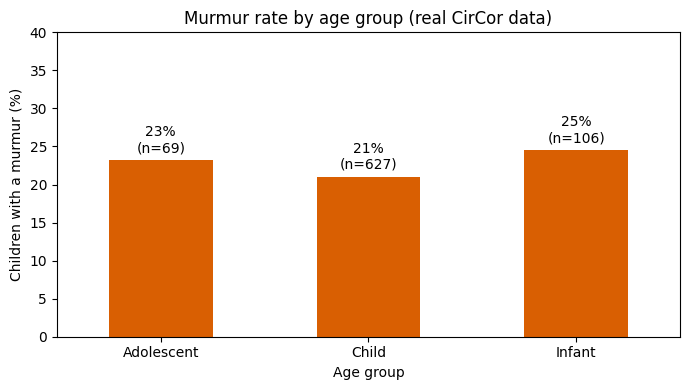

In [59]:
known = heart_track[heart_track["Murmur"].isin(["Absent", "Present"])].copy()
known["Age"] = known["Age"].replace({"Neonate": "Infant"})

rate = pd.crosstab(known["Age"], known["Murmur"], normalize="index")["Present"] * 100
counts = known["Age"].value_counts()

ax = rate.plot(kind="bar", color="#d95f02", figsize=(7, 4))
ax.set_ylabel("Children with a murmur (%)")
ax.set_xlabel("Age group")
ax.set_title("Murmur rate by age group (real CirCor data)")
ax.set_ylim(0, 40)
for i, (age, val) in enumerate(rate.items()):
    ax.text(i, val + 1, f"{val:.0f}%\n(n={counts[age]})", ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

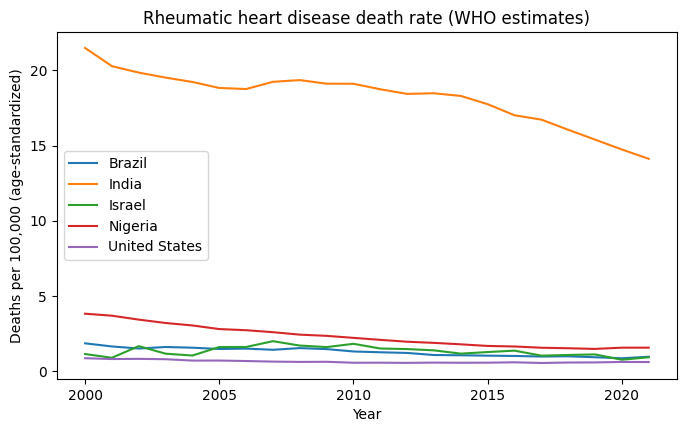

In [60]:
val = death_rate.columns[-1]

def plot_countries(selected, log_scale=False):
    if len(selected) == 0:
        print("Pick at least one country (hold Ctrl or Cmd to select several).")
        return
    subset = death_rate[death_rate["Entity"].isin(selected)]
    plt.figure(figsize=(8, 4.5))
    for name, g in subset.groupby("Entity"):
        plt.plot(g["Year"], g[val], label=name)
    if log_scale:
        plt.yscale("log")
    plt.title("Rheumatic heart disease death rate (WHO estimates)")
    plt.xlabel("Year")
    plt.ylabel("Deaths per 100,000 (age-standardized)")
    plt.legend()
    plt.show()

five = ("Israel", "India", "Brazil", "Nigeria", "United States")
plot_countries(five)

Rheumatic heart disease death rates fell between 2000 and 2021 in all five places, but remain many times higher in India and Nigeria than in Israel, Brazil and the United States. These are WHO estimates of deaths, not of when a condition is diagnosed, so they are context and not proof.

In [61]:
places = sorted(death_rate["Entity"].unique())

_ = widgets.interact(
    plot_countries,
    selected=widgets.SelectMultiple(options=places, value=five, description="Countries", rows=8),
    log_scale=widgets.Checkbox(value=False, description="Log scale"),
)

interactive(children=(SelectMultiple(description='Countries', index=(86, 81, 25, 129, 191), options=('Afghanis…

## 8. Limits and disclaimer

- The 300 children, their daily logs, symptoms and worse weeks are **simulated**. The size of the gaps between murmur-flagged and other children is my assumption, so the tests show the tracker can find the pattern, not that it exists in real children.
- The 80%, 110% and 4-day thresholds are design choices, not medical rules. Some false alarms and misses are expected.
- Poor weight gain is simulated as a daily yes or no, though in real life it is a slow trend.
- Real data used: CirCor DigiScope (children), UCI Heart Disease (adults, side analysis) and WHO estimates (countries).
- Educational project only. It does not diagnose anything. Blue lips, fainting or trouble breathing need urgent medical care.

**Sources:** CirCor DigiScope (PhysioNet), UCI Heart Disease, Our World in Data / WHO Global Health Estimates, and symptom lists from NHLBI, Mayo Clinic, CDC and NHS.